# ECG Heartbeat Classification: Modeling, Evaluation and Deployment
This notebook runs the whole of Submission 2, top to bottom. It needs the output of `EDA.ipynb` (`data/processed/`) and the toolchain (`make toolchain`).

0. **Setup.** Load `configs/model.yaml`, import the ai8x layers.
1. **Baselines** (report section 4.1). Logistic regression and random forest on the beat plus RR features.
2. **Model selection** (section 4.4). The staged sweep of `configs/sweep.yaml`, scored on the validation records only.
3. **Final CNN** (sections 4.2, 4.3). The best run: layer table, training settings, learning curve.
4. **Quantisation** (section 4.5). `quantize.py` on the FP32 checkpoint (PTQ), then QAT fine-tuning and `quantize.py` again. The INT8 model is chosen on validation.
5. **DS2 evaluation** (sections 5.1 to 5.3). The test set is read here for the first time. Baselines, FP32 and INT8, once each.
6. **Noise robustness** (section 5.4). Noise from `nstdb` added to the raw DS2 signals at 12, 6 and 0 dB.
7. **Error analysis** (section 5.5). Misclassified beats, clean and at 0 dB.
8. **Deployment** (section 6). Network YAML, sample beat, `ai8xize.py`, the evidence table.
9. **Success criteria** (section 5.6).
10. **Report.** Copy figures and tables into `report/`, run the tests, build `report.pdf`.

Run it with *Restart kernel and run all*, or headless with `make model` from the project root. Runs already in `results/experiments.csv` are skipped unless `FORCE_TRAIN` is set.

Outputs:
- `results/experiments.csv`, `results/history/*.csv`, `results/checkpoints/*`
- `results/metrics.csv`, `results/confusion_matrix.*`, `results/noise_results.*`, `results/quantization_val.csv`, `results/deployment_evidence.csv`, `results/success_criteria.csv`
- figures `results/figures/*.png` and LaTeX tables `results/tables/*.tex`, copied to `report/figures/` and `report/tables/`
- `max78002/model_configuration/`, `max78002/quantization_output/`, `max78002/synthesis_output/`
- `report.pdf` in the project root

In [1]:
import shutil
import subprocess
import sys
from pathlib import Path

ROOT = Path('..').resolve()              # project root; every path below starts here
sys.path.insert(0, str(ROOT / 'src'))

import numpy as np
import pandas as pd

from ecg.config import deep_update, load_config, load_model_config
from ecg.constants import CLASS_NAMES
from ecg.datasets.loaders import load_split
from ecg.deployment import evidence, toolchain
from ecg.deployment.network_yaml import write_network_yaml
from ecg.deployment.sample_input import export_sample
from ecg.eda.latex import latex_table
from ecg.eda.style import apply_style
from ecg.evaluation import confusion, errors, plots
from ecg.evaluation.criteria import success_criteria
from ecg.evaluation.metrics import flat_scores
from ecg.evaluation.predict import baseline_predictor, cnn_predictor, cnn_scores
from ecg.evaluation.report import metrics_row, upsert_row
from ecg.models.cnn import layer_table
from ecg.noise.experiment import noisy_split, run_noise_experiment
from ecg.noise.nstdb import load_noise
from ecg.seed import set_seed
from ecg.training.checkpoint import fuse_checkpoint
from ecg.training.experiment_log import has_run
from ecg.training.runner import run_baseline, run_cnn_training
from ecg.training.sweep import overrides_of, run_sweep

cfg = load_model_config(ROOT / 'configs/model.yaml', ROOT)   # paths are made absolute here
RESULTS = Path(cfg['paths']['results'])
FIG, TAB, HIST = RESULTS / 'figures', RESULTS / 'tables', RESULTS / 'history'
CKPT, EXPERIMENTS = Path(cfg['paths']['checkpoints']), Path(cfg['paths']['experiments'])
MAX = Path(cfg['paths']['max78002'])
MODELCFG, QUANT, SYNTH = MAX / 'model_configuration', MAX / 'quantization_output', MAX / 'synthesis_output'
REPORT = ROOT / 'report'
for d in (FIG, TAB, HIST, CKPT, MODELCFG, QUANT, SYNTH):
    d.mkdir(parents=True, exist_ok=True)

FORCE_TRAIN = False      # True: forget results/experiments.csv and train every run again
RUN_TESTS = True         # section 10
BUILD_REPORT = True      # section 10, needs pdflatex and biber

if FORCE_TRAIN:
    EXPERIMENTS.unlink(missing_ok=True)
set_seed(cfg['seed'])    # same seed, same output
apply_style()
pd.set_option('display.width', 160)
ai8x = toolchain.import_ai8x(cfg)   # the Analog Devices layer wrappers, MAX78002 selected
print('model', cfg['name'], '| window', cfg['input_length'], '| ai8x from', cfg['toolchain']['training'])

model cnn_base | window 256 | ai8x from /home/a476078/projects/D7043E/toolchain/ai8x-training


## 1 Baselines (report section 4.1)
Logistic regression and random forest on the flattened beat plus the three RR-interval features, scored on the validation records. `configs/baselines.yaml` holds their settings.

In [2]:
base = load_config(ROOT / 'configs/baselines.yaml')
for run in base['runs']:
    bcfg = load_model_config(ROOT / 'configs/baselines.yaml', ROOT, {'name': run['name'], 'model': run['model']})
    if not has_run(EXPERIMENTS, bcfg['name']):
        run_baseline(bcfg)
BASE_PRE, BASE_PROCESSED = bcfg['preprocess'], bcfg['paths']['processed']   # the baselines use the 256-sample window
VAL_COLS = ['name', 'n_params', 'val_accuracy', 'val_macro_f1', 'val_precision_S', 'val_recall_S', 'val_recall_V', 'val_recall_F']
exp = pd.read_csv(EXPERIMENTS)
baselines = exp[exp['model'] != 'cnn1d'][VAL_COLS].round(3)
t = baselines.copy()
t['name'] = t['name'].map({'baseline_lr': 'Logistic regression', 'baseline_rf': 'Random forest'})
t.columns = ['Model', 'Params', 'Accuracy', 'Macro-F1', 'S prec.', 'S recall', 'V recall', 'F recall']
(TAB / 'baselines.tex').write_text(latex_table(
    t, 'Baselines on the validation records. Both see the flattened beat plus the three RR features. Params: coefficients for the logistic regression, tree nodes for the forest.',
    'tab:baselines', align='lRRRRRRR'))
baselines

,name,n_params,val_accuracy,val_macro_f1,val_precision_S,val_recall_S,val_recall_V,val_recall_F
0,baseline_lr,1040,0.894,0.462,0.254,0.319,0.535,0.125
1,baseline_rf,150574,0.933,0.430,0.933,0.043,0.529,0.000


## 2 Model selection (report section 4.4)
The staged sweep of `configs/sweep.yaml`. Stage 1 compares ways to handle the class imbalance, stage 2 varies architecture, regularisation, augmentation and the beat window, stage 3 varies the rest again around the stage-2 winner. Every run is scored on the validation records; DS2 is never read here. Runs already in `results/experiments.csv` are skipped.

In [3]:
sweep = run_sweep(load_config(ROOT / 'configs/sweep.yaml'), ROOT / 'configs/model.yaml', ROOT, HIST)
SWEEP_COLS = ['name', 'stage', 'window', 'n_params', 'best_epoch', 'val_accuracy', 'val_macro_f1',
              'val_precision_S', 'val_recall_S', 'val_recall_V', 'val_recall_F']
sweep[SWEEP_COLS].round(3)

2026-11-05 16:54:38,443 INFO ecg.training.sweep: stage 1 (class imbalance) starts from model.yaml


2026-11-05 16:54:38,453 INFO ecg.training.sweep: cnn_weights_oversample_fp32 already in the log, skipped


2026-11-05 16:54:38,464 INFO ecg.training.sweep: cnn_weights_only_fp32 already in the log, skipped


2026-11-05 16:54:38,475 INFO ecg.training.sweep: cnn_oversample_only_fp32 already in the log, skipped


2026-11-05 16:54:38,488 INFO ecg.training.sweep: cnn_mild_balance_fp32 already in the log, skipped


2026-11-05 16:54:38,500 INFO ecg.training.sweep: cnn_focal_fp32 already in the log, skipped


... (11 outputs left out)

2026-11-05 16:54:38,615 INFO ecg.training.sweep: cnn_w512_no_aug_fp32 already in the log, skipped


2026-11-05 16:54:38,624 INFO ecg.training.sweep: cnn_w512_small_fp32 already in the log, skipped


2026-11-05 16:54:38,634 INFO ecg.training.sweep: cnn_w512_large_fp32 already in the log, skipped


,name,stage,window,n_params,best_epoch,val_accuracy,val_macro_f1,val_precision_S,val_recall_S,val_recall_V,val_recall_F
0,cnn_w512_batchnorm_fp32,3,512,25700,18.0,0.965,0.667,0.846,0.401,0.840,0.219
1,cnn_w512_mild_balance_fp32,3,512,25348,35.0,0.951,0.614,0.616,0.444,0.802,0.281
2,cnn_w512_large_fp32,3,512,39300,28.0,0.949,0.613,0.478,0.429,0.848,0.344
3,cnn_w512_small_fp32,3,512,7428,6.0,0.954,0.598,0.567,0.362,0.835,0.219
4,cnn_w512_no_aug_fp32,3,512,25348,9.0,0.946,0.596,0.454,0.453,0.788,0.219
5,cnn_w512_fp32,2,512,25348,4.0,0.947,0.591,0.472,0.465,0.736,0.156
6,cnn_oversample_only_fp32,1,256,25348,8.0,0.955,0.569,0.441,0.237,0.929,0.156
7,cnn_mild_balance_fp32,1,256,25348,6.0,0.946,0.564,0.471,0.219,0.923,0.312
8,cnn_no_aug_fp32,2,256,25348,5.0,0.938,0.562,0.544,0.280,0.833,0.250
9,cnn_batchnorm_fp32,2,256,25700,20.0,0.951,0.557,0.416,0.286,0.920,0.031


In [4]:
# The table for report section 4.4: every run, best first.
t = sweep[SWEEP_COLS].round(3).copy()
t['name'] = t['name'].str.replace('_fp32', '').str.replace('_', r'\_')
t.columns = ['Run', 'Stage', 'Window', 'Params', 'Best epoch', 'Accuracy', 'Macro-F1', 'S prec.', 'S recall', 'V recall', 'F recall']
t['Best epoch'] = t['Best epoch'].astype(int)
(TAB / 'model_selection.tex').write_text(latex_table(
    t, 'Model-selection sweep on the validation records, best first. Window is the input length in samples.',
    'tab:model-selection', align='l' + 'R' * (t.shape[1] - 1)))
t

,Run,Stage,Window,Params,Best epoch,Accuracy,Macro-F1,S prec.,S recall,V recall,F recall
0,cnn\_w512\_batchnorm,3,512,25700,18,0.965,0.667,0.846,0.401,0.840,0.219
1,cnn\_w512\_mild\_balance,3,512,25348,35,0.951,0.614,0.616,0.444,0.802,0.281
2,cnn\_w512\_large,3,512,39300,28,0.949,0.613,0.478,0.429,0.848,0.344
3,cnn\_w512\_small,3,512,7428,6,0.954,0.598,0.567,0.362,0.835,0.219
4,cnn\_w512\_no\_aug,3,512,25348,9,0.946,0.596,0.454,0.453,0.788,0.219
5,cnn\_w512,2,512,25348,4,0.947,0.591,0.472,0.465,0.736,0.156
6,cnn\_oversample\_only,1,256,25348,8,0.955,0.569,0.441,0.237,0.929,0.156
7,cnn\_mild\_balance,1,256,25348,6,0.946,0.564,0.471,0.219,0.923,0.312
8,cnn\_no\_aug,2,256,25348,5,0.938,0.562,0.544,0.280,0.833,0.250
9,cnn\_batchnorm,2,256,25700,20,0.951,0.557,0.416,0.286,0.920,0.031


## 3 The final CNN (report sections 4.2 and 4.3)
The best sweep run is the final FP32 model. Its config is rebuilt from the overrides stored in the log, so everything below (quantisation, synthesis, noise test) uses exactly the layers that were trained.

In [5]:
best = sweep.iloc[0]
overrides = overrides_of(best)
overrides['name'] = best['name'].removesuffix('_fp32')
cfg = load_model_config(ROOT / 'configs/model.yaml', ROOT, overrides)
FINAL = cfg['name']
FP32 = CKPT / f'{FINAL}_fp32.pth.tar'
PRE = cfg['preprocess']                       # the preprocessing config of the final window
print('final model:', FINAL, '| window', cfg['input_length'], '| validation macro-F1', round(best['val_macro_f1'], 3))
print('model:', cfg['model'])
print('training:', {k: cfg['training'][k] for k in ('loss', 'class_weight_power', 'oversample_power', 'lr', 'batch_size')})
layers = layer_table(cfg['model'], cfg['input_length'])
layers.to_csv(RESULTS / 'model_layers.csv', index=False)
(TAB / 'model_layers.tex').write_text(latex_table(
    layers, 'Layers of the final CNN as the accelerator runs them. Each row is one fused layer; the pool, when present, runs before the convolution.',
    'tab:architecture', align='llYlr'))
layers

final model: cnn_w512_batchnorm | window 512 | validation macro-F1 0.667
model: {'type': 'cnn1d', 'channels': [16, 32, 64, 64], 'kernels': [5, 5, 3, 3], 'paddings': [2, 2, 1, 1], 'pools': [1, 2, 4, 4], 'batchnorm': True, 'dropout': 0.0, 'num_classes': 4}
training: {'loss': 'ce', 'class_weight_power': 0.5, 'oversample_power': 0.5, 'lr': 0.001, 'batch_size': 128}


,Layer,Input,Operation,Output,Parameters
0,conv1,1 x 512,"Conv1d k=5 p=2, ReLU",16 x 512,96
1,conv2,16 x 512,"MaxPool 2, Conv1d k=5 p=2, ReLU",32 x 256,2592
2,conv3,32 x 256,"MaxPool 4, Conv1d k=3 p=1, ReLU",64 x 64,6208
3,conv4,64 x 64,"MaxPool 4, Conv1d k=3 p=1, ReLU",64 x 16,12352
4,fc,1024 (flattened),Linear,4,4100
5,Total,,,,25348


In [6]:
# Training settings of the final run, for report section 4.3.
tr, aug = cfg['training'], cfg['augmentation']
balance = {'ce': 'none', 'weighted_ce': f"inverse frequency to the power {tr.get('class_weight_power', 0.5)}",
           'focal': f"focal loss (gamma {tr.get('focal_gamma', 2.0)}) with inverse-frequency weights"}[tr['loss']]
aug_text = ('amplitude scaling %s, time shift $\\pm$%d samples, baseline wander up to %.1f, Gaussian noise $\\sigma$ = %.2f'
            % (aug['amplitude_scale'], aug['shift_samples'], aug['baseline_wander_amplitude'], aug['gaussian_noise_std'])) if aug.get('enabled', True) else 'none'
settings = pd.DataFrame([
    ('Input', f"1 $\\times$ {cfg['input_length']} samples, scaled to $[-1, 1)$"),
    ('Optimizer', 'Adam, weight decay %g' % tr.get('weight_decay', 0.0)),
    ('Learning rate', f"{tr['lr']}, cosine decay over {tr['epochs']} epochs"),
    ('Batch size', tr['batch_size']),
    ('Epochs', f"at most {tr['epochs']}; stopped after {int(best['epochs_run'])}, best epoch {int(best['best_epoch'])}"),
    ('Loss', {'ce': 'cross-entropy', 'weighted_ce': 'class-weighted cross-entropy', 'focal': 'focal loss'}[tr['loss']]),
    ('Class weighting', balance),
    ('Oversampling', f"sampler weight (1 / class frequency) to the power {tr.get('oversample_power', 0)}" if tr.get('oversample_power', 0) else 'none'),
    ('Early stopping', f"patience {tr['early_stopping_patience']} epochs on validation macro-F1"),
    ('Augmentation', aug_text),
    ('Dropout', cfg['model'].get('dropout', 0.0)),
    ('Random seed', cfg['seed']),
], columns=['Setting', 'Value'])
(TAB / 'training_config.tex').write_text(latex_table(settings, 'Training configuration of the final model.', 'tab:training-config', align='lY'))
settings

,Setting,Value
0,Input,"1 $\times$ 512 samples, scaled to $[-1, 1)$"
1,Optimizer,"Adam, weight decay 0"
2,Learning rate,"0.001, cosine decay over 60 epochs"
3,Batch size,128
4,Epochs,"at most 60; stopped after 28, best epoch 18"
5,Loss,cross-entropy
6,Class weighting,none
7,Oversampling,sampler weight (1 / class frequency) to the po...
8,Early stopping,patience 10 epochs on validation macro-F1
9,Augmentation,"amplitude scaling [0.8, 1.2], time shift $\pm$..."


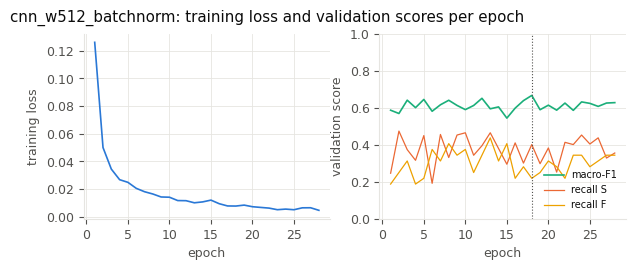

In [7]:
hist = pd.read_csv(HIST / f'{FINAL}_fp32.csv')
plots.learning_curve(hist, f'{FINAL}: training loss and validation scores per epoch').savefig(FIG / 'learning_curve.png')

## 4 Quantisation (report section 4.5)
Two INT8 models are made with `quantize.py` from ai8x-synthesis: one straight from the FP32 checkpoint (after folding BatchNorm into the conv weights, which the accelerator needs) (post-training quantisation, PTQ), and one after quantisation-aware fine-tuning (QAT) with `ai8x.initiate_qat`. Both are scored on the validation records in the ai8x integer simulation, and the better one is the deployed model. DS2 is still untouched.

In [8]:
VAL = load_split(cfg['paths']['processed'], 'val')
FUSED = fuse_checkpoint(cfg, ai8x, FP32, CKPT / f'{FINAL}_fp32_fused.pth.tar')   # BatchNorm folded into the conv weights
PTQ = QUANT / f'{FINAL}_ptq-q.pth.tar'
ok_ptq = toolchain.run_quantize(cfg, FUSED, PTQ, QUANT / f'{FINAL}_ptq_quantize.log')
print('PTQ', 'ok' if ok_ptq else 'FAILED, see the log')
rows = [{'model': 'FP32', **flat_scores(VAL['y'], cnn_predictor(cfg, FP32)(VAL['X'], VAL['rr']))},
        {'model': 'INT8, post-training (PTQ)', **flat_scores(VAL['y'], cnn_predictor(cfg, PTQ, int8=True)(VAL['X'], VAL['rr']))}]
pd.DataFrame(rows).round(3)

PTQ ok


,model,accuracy,macro_f1,precision_N,recall_N,f1_N,precision_S,recall_S,f1_S,precision_V,recall_V,f1_V,precision_F,recall_F,f1_F
0,FP32,0.965,0.667,0.974,0.997,0.985,0.846,0.401,0.544,0.878,0.840,0.859,0.389,0.219,0.28
1,"INT8, post-training (PTQ)",0.931,0.393,0.947,0.997,0.971,0.000,0.000,0.000,0.671,0.544,0.601,0.000,0.000,0.00


In [9]:
QAT = CKPT / f'{FINAL}_qat.pth.tar'
if not has_run(EXPERIMENTS, f'{FINAL}_qat'):
    r = run_cnn_training(cfg, ai8x, qat_from=FP32)    # fine-tunes the FP32 weights with 8-bit weights and clamped activations
    r['history'].to_csv(HIST / f'{FINAL}_qat.csv', index=False)
QATQ = QUANT / f'{FINAL}_qat-q.pth.tar'
ok_qat = toolchain.run_quantize(cfg, QAT, QATQ, QUANT / f'{FINAL}_qat_quantize.log')
print('QAT', 'ok' if ok_qat else 'FAILED, see the log')
rows.append({'model': 'INT8, after QAT', **flat_scores(VAL['y'], cnn_predictor(cfg, QATQ, int8=True)(VAL['X'], VAL['rr']))})
qval = pd.DataFrame(rows)
qval.to_csv(RESULTS / 'quantization_val.csv', index=False)
INT8 = QATQ if qval.loc[2, 'macro_f1'] >= qval.loc[1, 'macro_f1'] else PTQ
INT8_KIND = 'QAT' if INT8 == QATQ else 'PTQ'
ok_quant = ok_qat if INT8 == QATQ else ok_ptq
print('deployed INT8 model:', INT8_KIND, INT8.name)
t = qval[['model', 'accuracy', 'macro_f1'] + [f'recall_{c}' for c in CLASS_NAMES]].round(3)
t.columns = ['Model', 'Accuracy', 'Macro-F1'] + [f'{c} recall' for c in CLASS_NAMES]
(TAB / 'quantization_val.tex').write_text(latex_table(
    t, 'FP32 and INT8 versions of the final model on the validation records. INT8 scores come from the ai8x integer simulation of the quantised checkpoint.',
    'tab:quantization-val', align='lRRRRRR'))
t

QAT ok


deployed INT8 model: QAT cnn_w512_batchnorm_qat-q.pth.tar


,Model,Accuracy,Macro-F1,N recall,S recall,V recall,F recall
0,FP32,0.965,0.667,0.997,0.401,0.840,0.219
1,"INT8, post-training (PTQ)",0.931,0.393,0.997,0.000,0.544,0.000
2,"INT8, after QAT",0.959,0.659,0.994,0.359,0.806,0.344


## 5 Final evaluation on DS2 (report sections 5.1 to 5.3)
The test split is read here for the first time (`final=True`). Every model is scored once, on DS2 built with its own window (256 samples for the baselines, the final window for the CNN; the records and beats are the same). Nothing is tuned after this point.

,n_params,split,window,accuracy,macro_f1,precision_N,recall_N,f1_N,precision_S,recall_S,f1_S,precision_V,recall_V,f1_V,precision_F,recall_F,f1_F
model,,,,,,,,,,,,,,,,,
baseline_lr,1040,DS2,256,0.782,0.484,0.963,0.799,0.874,0.211,0.214,0.212,0.712,0.889,0.790,0.032,0.580,0.060
baseline_rf,150574,DS2,256,0.935,0.461,0.941,0.991,0.965,0.500,0.003,0.005,0.936,0.817,0.873,0.000,0.000,0.000
cnn_fp32,25700,DS2,512,0.921,0.505,0.953,0.961,0.957,0.143,0.127,0.135,0.888,0.928,0.908,0.056,0.013,0.021
cnn_int8,25348,DS2,512,0.916,0.493,0.954,0.955,0.954,0.122,0.114,0.118,0.855,0.943,0.897,0.008,0.003,0.004


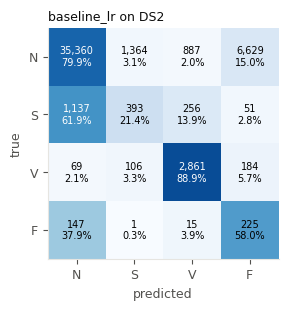

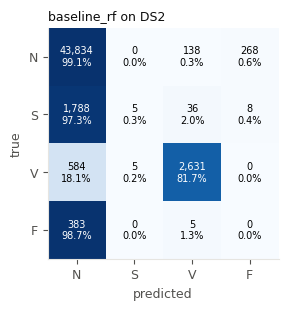

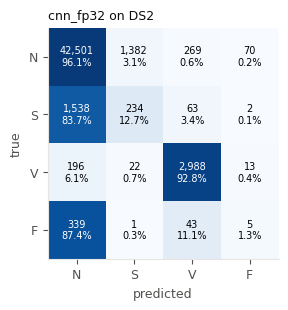

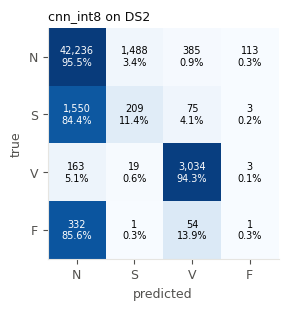

In [10]:
TEST = load_split(cfg['paths']['processed'], 'test', final=True)        # DS2 with the final CNN's window
TEST_BASE = load_split(BASE_PROCESSED, 'test', final=True)               # DS2 with the baselines' 256-sample window
data_for = {'baseline_lr': TEST_BASE, 'baseline_rf': TEST_BASE, 'cnn_fp32': TEST, 'cnn_int8': TEST}
predictors = {'baseline_lr': baseline_predictor(CKPT / 'baseline_lr.joblib'),
              'baseline_rf': baseline_predictor(CKPT / 'baseline_rf.joblib'),
              'cnn_fp32': cnn_predictor(cfg, FP32),
              'cnn_int8': cnn_predictor(cfg, INT8, int8=True)}
deployed_params = int(layers.loc[layers['Layer'] == 'Total', 'Parameters'].iloc[0])   # after BatchNorm folding
n_params = {**exp.set_index('name')['n_params'].to_dict(), 'cnn_fp32': int(best['n_params']), 'cnn_int8': deployed_params}
preds = {}
for name, predict in predictors.items():
    d = data_for[name]
    preds[name] = predict(d['X'], d['rr'])
    upsert_row(RESULTS / 'metrics.csv', metrics_row(name, d['y'], preds[name], n_params[name], split='DS2', window=d['X'].shape[-1]))
    cm = confusion.compute(d['y'], preds[name])
    confusion.save_csv(cm, RESULTS / f'confusion_matrix_{name}.csv')
    plots.confusion_matrix(cm, f'{name} on DS2').savefig(FIG / f'confusion_matrix_{name}.png')
for ext in ('csv', 'png'):   # the deployed model's matrix under the name the assignment asks for
    shutil.copy2((RESULTS if ext == 'csv' else FIG) / f'confusion_matrix_cnn_int8.{ext}', RESULTS / f'confusion_matrix.{ext}')
metrics = pd.read_csv(RESULTS / 'metrics.csv').set_index('model')
metrics.round(3)

In [11]:
# Section 5.1: metric by model.
names = {'baseline_lr': 'Logistic regression', 'baseline_rf': 'Random forest', 'cnn_fp32': 'FP32 CNN', 'cnn_int8': f'INT8 CNN ({INT8_KIND})'}
t = pd.DataFrame({names[m]: [f"{metrics.loc[m, 'accuracy']:.3f}", f"{metrics.loc[m, 'macro_f1']:.3f}", int(metrics.loc[m, 'n_params'])]
                  for m in names}, index=['Accuracy', 'Macro-F1', 'Model parameters']).reset_index().rename(columns={'index': 'Metric'})
(TAB / 'clean_results.tex').write_text(latex_table(
    t, 'Clean DS2 test results. The parameter count of the random forest is its number of tree nodes.', 'tab:clean-results', align='lRRRR'))
t

,Metric,Logistic regression,Random forest,FP32 CNN,INT8 CNN (QAT)
0,Accuracy,0.782,0.935,0.921,0.916
1,Macro-F1,0.484,0.461,0.505,0.493
2,Model parameters,1040,150574,25700,25348


In [12]:
# Section 5.2: per-class scores of the deployed INT8 model and of the FP32 model.
rows = []
for m, label in (('cnn_int8', f'INT8 ({INT8_KIND})'), ('cnn_fp32', 'FP32')):
    for c in CLASS_NAMES:
        rows.append({'Model': label, 'Class': c, 'Precision': round(metrics.loc[m, f'precision_{c}'], 3),
                     'Recall': round(metrics.loc[m, f'recall_{c}'], 3), 'F1': round(metrics.loc[m, f'f1_{c}'], 3),
                     'Beats': int((TEST['y'] == CLASS_NAMES.index(c)).sum())})
t = pd.DataFrame(rows)
(TAB / 'per_class.tex').write_text(latex_table(t, 'Per-class performance on DS2.', 'tab:per-class', align='llRRRR'))
t

,Model,Class,Precision,Recall,F1,Beats
0,INT8 (QAT),N,0.954,0.955,0.954,44222
1,INT8 (QAT),S,0.122,0.114,0.118,1837
2,INT8 (QAT),V,0.855,0.943,0.897,3219
3,INT8 (QAT),F,0.008,0.003,0.004,388
4,FP32,N,0.953,0.961,0.957,44222
5,FP32,S,0.143,0.127,0.135,1837
6,FP32,V,0.888,0.928,0.908,3219
7,FP32,F,0.056,0.013,0.021,388


,Quantity,Value
0,FP32 macro-F1,0.505
1,INT8 macro-F1 (QAT),0.493
2,Difference (FP32 minus INT8),0.012


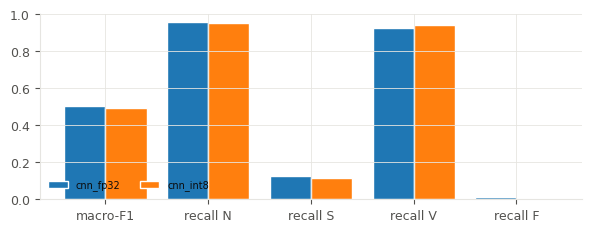

In [13]:
# Section 5.3: FP32 versus INT8 on DS2.
diff = metrics.loc['cnn_fp32', 'macro_f1'] - metrics.loc['cnn_int8', 'macro_f1']
t = pd.DataFrame([('FP32 macro-F1', f"{metrics.loc['cnn_fp32', 'macro_f1']:.3f}"),
                  (f'INT8 macro-F1 ({INT8_KIND})', f"{metrics.loc['cnn_int8', 'macro_f1']:.3f}"),
                  ('Difference (FP32 minus INT8)', f'{diff:.3f}')], columns=['Quantity', 'Value'])
(TAB / 'quantization_ds2.tex').write_text(latex_table(t, 'Effect of quantisation on DS2.', 'tab:quantization-ds2', align='lR'))
plots.fp32_vs_int8(metrics.reset_index(), ['cnn_fp32', 'cnn_int8']).savefig(FIG / 'fp32_vs_int8.png')
t

## 6 Noise robustness (report section 5.4)
Noise from the Noise Stress Test Database (`bw`, `em`, `ma`) is added to the raw DS2 signals at 12, 6 and 0 dB, then the same preprocessing as in training runs, then the frozen models predict. The small and large CNNs from the sweep (same window) show robustness against model size, and one run with the 40 Hz low-pass filter switched off shows whether the preprocessing helps.

2026-11-05 16:54:50,917 INFO ecg.noise.experiment: cnn_int8 noise=none snr=clean macro_f1=0.493 acc=0.916


2026-11-05 16:54:51,530 INFO ecg.noise.experiment: cnn_fp32 noise=none snr=clean macro_f1=0.505 acc=0.921


2026-11-05 16:54:52,409 INFO ecg.noise.experiment: cnn_w512_large_fp32 noise=none snr=clean macro_f1=0.445 acc=0.871


2026-11-05 16:54:52,798 INFO ecg.noise.experiment: cnn_w512_small_fp32 noise=none snr=clean macro_f1=0.452 acc=0.902


2026-11-05 16:54:56,728 INFO ecg.noise.experiment: cnn_int8 noise=bw snr=12 macro_f1=0.495 acc=0.916


2026-11-05 16:54:57,315 INFO ecg.noise.experiment: cnn_fp32 noise=bw snr=12 macro_f1=0.505 acc=0.921


... (51 outputs left out)

2026-11-05 18:45:35,694 INFO ecg.noise.experiment: baseline_rf noise=ma snr=12 macro_f1=0.459 acc=0.936


2026-11-05 18:45:38,074 INFO ecg.noise.experiment: baseline_rf noise=ma snr=6 macro_f1=0.457 acc=0.936


2026-11-05 18:45:40,483 INFO ecg.noise.experiment: baseline_rf noise=ma snr=0 macro_f1=0.452 acc=0.936


,model,noise,snr_db,accuracy,macro_f1,f1_N,f1_S,f1_V,f1_F
0,cnn_int8,none,clean,0.916,0.493,0.954,0.118,0.897,0.004
1,cnn_fp32,none,clean,0.921,0.505,0.957,0.135,0.908,0.021
2,cnn_w512_large_fp32,none,clean,0.871,0.445,0.931,0.100,0.739,0.012
3,cnn_w512_small_fp32,none,clean,0.902,0.452,0.949,0.105,0.715,0.041
4,cnn_int8,bw,12,0.916,0.495,0.955,0.118,0.898,0.008
5,cnn_fp32,bw,12,0.921,0.505,0.958,0.136,0.909,0.017
6,cnn_w512_large_fp32,bw,12,0.870,0.445,0.930,0.098,0.738,0.013
7,cnn_w512_small_fp32,bw,12,0.900,0.454,0.948,0.110,0.712,0.046
8,cnn_int8,bw,6,0.916,0.496,0.955,0.120,0.896,0.011
9,cnn_fp32,bw,6,0.922,0.504,0.958,0.137,0.905,0.017


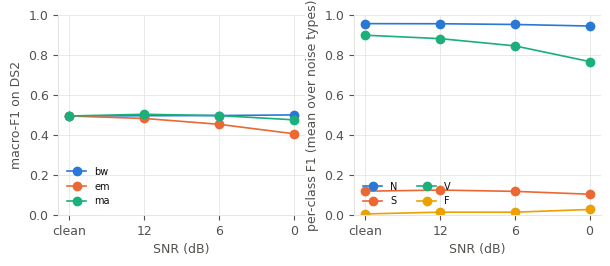

In [14]:
noise_cfg = load_config(ROOT / 'configs/noise.yaml')
noise_predictors = {'cnn_int8': predictors['cnn_int8'], 'cnn_fp32': predictors['cnn_fp32']}
same_window = sweep[(sweep['window'] == cfg['input_length']) & sweep['name'].str.contains('small|large')]
for _, row in same_window.iterrows():
    rcfg = load_model_config(ROOT / 'configs/model.yaml', ROOT, overrides_of(row))
    noise_predictors[row['name']] = cnn_predictor(rcfg, CKPT / f"{row['name']}.pth.tar")
noise = run_noise_experiment(cfg, noise_predictors, noise_cfg['noise_types'], noise_cfg['snr_db'])
no_lowpass = deep_update(PRE, {'filter': {'lowpass_hz': None}})
noise_nolp = run_noise_experiment(cfg, {'cnn_int8_no_lowpass': predictors['cnn_int8']}, noise_cfg['noise_types'], noise_cfg['snr_db'], pre_cfg=no_lowpass)
noise_base = run_noise_experiment(cfg, {'baseline_rf': predictors['baseline_rf']}, noise_cfg['noise_types'], noise_cfg['snr_db'], pre_cfg=BASE_PRE)
noise = pd.concat([noise, noise_nolp, noise_base], ignore_index=True)
noise.to_csv(RESULTS / 'noise_results.csv', index=False)
plots.noise_curve(noise, 'cnn_int8').savefig(FIG / 'noise_results.png')
noise[['model', 'noise', 'snr_db', 'accuracy', 'macro_f1'] + [f'f1_{c}' for c in CLASS_NAMES]].round(3)

In [15]:
# Section 5.4 tables. First the deployed model by SNR, averaged over the three noise types.
d = noise[noise['model'] == 'cnn_int8'].copy()
d['Condition'] = d['snr_db'].map(lambda s: 'Clean' if s == 'clean' else f'{s} dB')
by_snr = d.groupby('Condition', sort=False)[['accuracy', 'macro_f1'] + [f'f1_{c}' for c in CLASS_NAMES]].mean().round(3).reset_index()
by_snr.columns = ['Condition', 'Accuracy', 'Macro-F1'] + [f'F1 {c}' for c in CLASS_NAMES]
(TAB / 'noise_results.tex').write_text(latex_table(
    by_snr, 'INT8 model on DS2 under increasing noise, averaged over the three noise types.', 'tab:noise', align='lRRRRRR'))
# Then macro-F1 of every model for every noise type and SNR.
p = noise.copy()
p['snr_db'] = pd.Categorical(p['snr_db'].astype(str), ['clean', '12', '6', '0'])
p['noise'] = pd.Categorical(p['noise'].map({'none': 'clean', 'bw': 'baseline wander', 'em': 'electrode motion', 'ma': 'muscle artefact'}),
                            ['clean', 'baseline wander', 'electrode motion', 'muscle artefact'])
pivot = p.pivot_table(index=['noise', 'snr_db'], columns='model', values='macro_f1', observed=True)
order = [c for c in ['cnn_int8', 'cnn_fp32', 'cnn_int8_no_lowpass', 'baseline_rf'] + sorted(same_window['name']) if c in pivot.columns]
pivot = pivot[order].reset_index()
pivot.columns = ['Noise', 'SNR (dB)'] + [(c.replace('_fp32', '') if c.startswith('cnn_w512') else c).replace('_', r'\_') for c in order]
(TAB / 'noise_by_type.tex').write_text(latex_table(
    pivot, 'Macro-F1 on DS2 for every noise type and SNR. no\\_lowpass: the INT8 model with the 40 Hz filter switched off.',
    'tab:noise-by-type', align='lR' + 'R' * len(order)))
pivot

,Noise,SNR (dB),cnn\_int8,cnn\_fp32,cnn\_int8\_no\_lowpass,baseline\_rf,cnn\_w512\_large,cnn\_w512\_small
0,clean,clean,0.493177,0.505190,0.497314,0.460812,0.445326,0.452455
1,baseline wander,12,0.494573,0.504976,0.497025,0.460751,0.444833,0.454039
2,baseline wander,6,0.495514,0.504088,0.499120,0.460929,0.443237,0.455265
3,baseline wander,0,0.498583,0.503504,0.499840,0.459733,0.444300,0.458616
4,electrode motion,12,0.480792,0.484212,0.484465,0.451565,0.420392,0.436873
5,electrode motion,6,0.451806,0.453508,0.454407,0.436029,0.385617,0.404395
6,electrode motion,0,0.404521,0.401910,0.408019,0.400561,0.338701,0.341840
7,muscle artefact,12,0.501642,0.507257,0.499401,0.459330,0.442876,0.450698
8,muscle artefact,6,0.495123,0.499240,0.489211,0.456852,0.436945,0.447923
9,muscle artefact,0,0.474055,0.475899,0.461002,0.452277,0.413482,0.429098


## 7 Error analysis (report section 5.5)
Misclassified beats of the deployed model on clean DS2, and beats that were right when clean but wrong at 0 dB muscle artefact.

beats correct when clean but wrong at 0 dB muscle artefact: 1134


,True to predicted,Clean DS2,"Muscle artefact, 0 dB"
0,N $\rightarrow$ S,1488,672
1,S $\rightarrow$ N,1550,1637
2,V $\rightarrow$ N,163,531
3,V $\rightarrow$ F,3,21
4,F $\rightarrow$ N,332,340
5,F $\rightarrow$ V,54,41


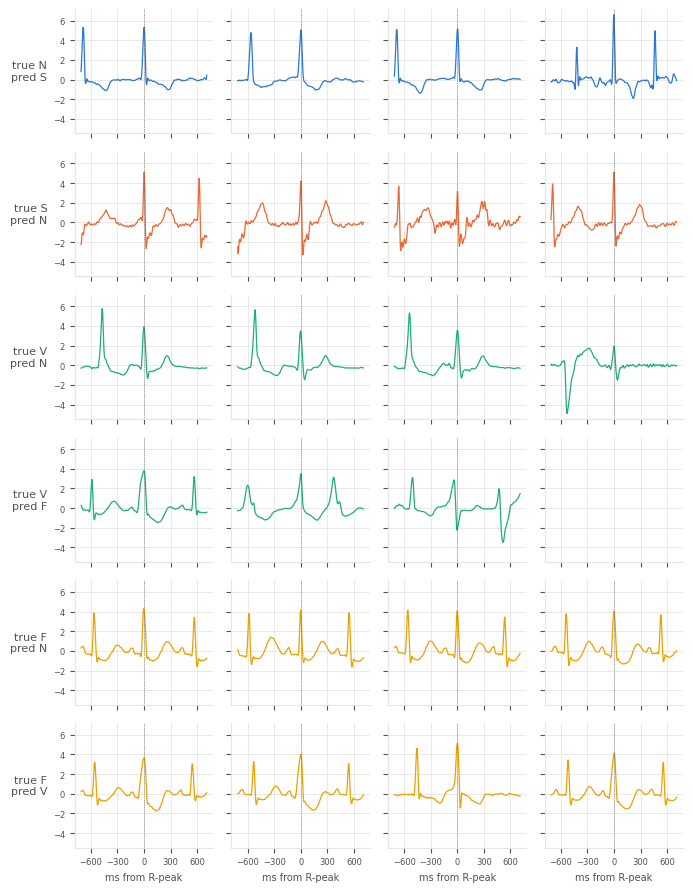

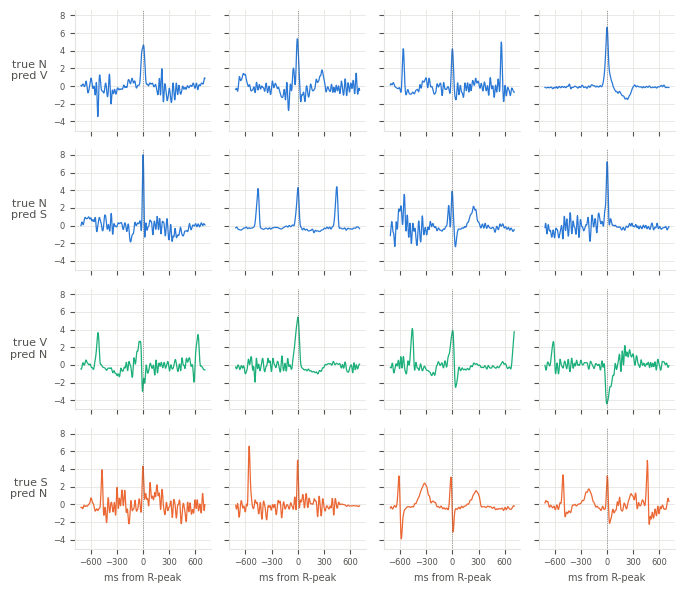

In [16]:
y_pred = preds['cnn_int8']
PAIRS = [('N', 'S'), ('S', 'N'), ('V', 'N'), ('V', 'F'), ('F', 'N'), ('F', 'V')]
picks = errors.select_examples(TEST['y'], y_pred, PAIRS, k=4, seed=cfg['seed'])
plots.error_examples(TEST['X'], picks, cfg['fs'], PRE['beat']['samples_before']).savefig(FIG / 'error_examples.png')
noisy = noisy_split(PRE, load_noise(cfg['paths']['raw_nstdb'], 'ma'), 0.0, cfg['seed'])   # the same DS2 beats, 0 dB muscle artefact
y_noisy = predictors['cnn_int8'](noisy['X'], noisy['rr'])
flipped = (y_pred == TEST['y']) & (y_noisy != TEST['y'])
picks_noise = errors.select_examples(TEST['y'][flipped], y_noisy[flipped], [('N', 'V'), ('N', 'S'), ('V', 'N'), ('S', 'N')], k=4, seed=cfg['seed'])
plots.error_examples(noisy['X'][flipped], picks_noise, cfg['fs'], PRE['beat']['samples_before']).savefig(FIG / 'error_examples_noise.png')
counts = pd.DataFrame({'Clean DS2': errors.error_counts(TEST['y'], y_pred, PAIRS),
                       'Muscle artefact, 0 dB': errors.error_counts(TEST['y'], y_noisy, PAIRS)})
counts.index.name = 'True to predicted'
counts = counts.reset_index()
counts['True to predicted'] = counts['True to predicted'].str.replace('->', ' $\\rightarrow$ ')
(TAB / 'error_counts.tex').write_text(latex_table(counts, 'Number of beats in the main error types, INT8 model.', 'tab:error-counts', align='lRR'))
print('beats correct when clean but wrong at 0 dB muscle artefact:', int(flipped.sum()))
counts

In [17]:
# Which DS2 records drive the errors: accuracy and the S and V counts per record, INT8 model.
per_record = errors.per_record_table(TEST['record_ids'], TEST['y'], y_pred)
per_record.to_csv(RESULTS / 'per_record_ds2.csv', index=False)
t = per_record.sort_values('accuracy').head(8).round(3)
(TAB / 'per_record_ds2.tex').write_text(latex_table(
    t, 'The eight DS2 records with the lowest accuracy of the INT8 model, with the true and predicted beat counts per class.',
    'tab:per-record', align='l' + 'R' * (t.shape[1] - 1)))
per_record.round(3)

,record,beats,accuracy,true N,pred N,true S,pred S,true V,pred V,true F,pred F
0,100,2271,0.996,2237,2246,33,24,1,1,0,0
1,103,2083,0.999,2081,2083,2,0,0,0,0,0
2,105,2566,0.968,2525,2469,0,0,41,91,0,6
3,111,2123,0.982,2122,2083,0,0,1,40,0,0
4,113,1793,0.998,1787,1787,6,3,0,3,0,0
5,117,1533,1.000,1532,1532,1,1,0,0,0,0
6,121,1861,0.998,1859,1858,1,0,1,3,0,0
7,123,1517,0.999,1514,1512,0,2,3,3,0,0
8,200,2599,0.978,1742,1788,30,14,825,797,2,0
9,202,2135,0.923,2060,1987,55,74,19,37,1,37


## 8 Deployment (report section 6)
`ai8xize.py` from ai8x-synthesis turns the INT8 checkpoint, the network YAML and one sample beat into the C project for the MAX78002. The synthesiser also computes the network output for the sample beat with its own model of the accelerator; the generated `main.c` checks that value on the device, and here it is compared with the Python INT8 simulation.

In [18]:
NET = MODELCFG / 'ecg-max78002.yaml'
write_network_yaml(cfg, NET)
SAMPLE = SYNTH / 'sample_ecg_mitbih.npy'
sample_beat = VAL['X'][int(np.flatnonzero(VAL['y'] == CLASS_NAMES.index('V'))[0])]   # a V beat from a validation record
export_sample(sample_beat, cfg['input_scale'], SAMPLE)
PREFIX = 'ecg-max78002'
ok_synth = toolchain.run_synthesis(cfg, INT8, NET, SAMPLE, SYNTH, PREFIX, SYNTH / 'ai8xize.log')
print('synthesis', 'ok' if ok_synth else 'FAILED, see max78002/synthesis_output/ai8xize.log')
log_text = (SYNTH / PREFIX / 'log.txt').read_text() if (SYNTH / PREFIX / 'log.txt').exists() else (SYNTH / 'ai8xize.log').read_text()
python_out = cnn_scores(cfg, INT8, sample_beat[None], int8=True)[0]
scale = evidence.output_scale(INT8)   # the software output scale; the accelerator value is the Python value divided by it
print('Python INT8 output for the sample beat:', (python_out / scale).astype(int), '| synthesiser:', evidence.expected_output(log_text))
ev = evidence.evidence_table(ok_quant, ok_synth, SYNTH / PREFIX, log_text,
                             evidence.data_memory_bytes(cfg['model'], cfg['input_length']), python_out, scale)
ev.to_csv(RESULTS / 'deployment_evidence.csv', index=False)
(TAB / 'deployment_evidence.tex').write_text(latex_table(ev, 'Deployment evidence from the MAX78002 toolchain (software only, no board).', 'tab:deployment-evidence', align='YlY'))
print(sorted(p.name for p in (SYNTH / PREFIX).iterdir()))
ev

synthesis ok
Python INT8 output for the sample beat: [ -1634 -21221   6834 -20374] | synthesiser: [ -1634 -21221   6834 -20374]
['.cproject', '.project', '.settings', '.vscode', 'Makefile', 'cnn.c', 'cnn.h', 'ecg-max78002.launch', 'log.txt', 'main.c', 'project.mk', 'sampledata.h', 'sampleoutput.h', 'softmax.c', 'weights.h']


,Requirement,Result,Evidence
0,Model accepted by MAX78002 toolchain,PASS,"ai8x layer checks, quantize.py and ai8xize.py ..."
1,Quantization completed,PASS,quantize.py log and the INT8 checkpoint
2,Synthesis completed,PASS,ai8xize.py exit code and log.txt
3,C/device files generated,PASS,"cnn.c, cnn.h, weights.h, main.c, sampledata.h,..."
4,Weight memory requirement,"25\,168 bytes of 2\,396\,160",RESOURCE USAGE in log.txt
5,Data memory requirement,"8\,192 bytes (largest activation) of 1\,310\,720",largest layer input or output; the MAX78002 ha...
6,Known-answer test: Python INT8 output equals s...,PASS,sampleoutput.h versus the Python INT8 simulati...


## 9 Success criteria (report section 5.6)
Each criterion of report section 1.4, checked against the DS2 results of the deployed INT8 model.

In [19]:
weight_bytes = evidence.memory_usage(log_text).get('weight_bytes', int(best['n_params']))
crit = success_criteria(metrics.reset_index(), noise, ev, weight_bytes)
crit.to_csv(RESULTS / 'success_criteria.csv', index=False)
(TAB / 'success_criteria.tex').write_text(latex_table(crit, 'Success criteria of Section 1.4 reviewed on DS2.', 'tab:criteria-review', align='lYYl'))
crit

,Criterion,Target,Result on DS2,Status
0,Predictive performance,macro-F1 $\geq$ 0.70 on DS2,0.493,Not achieved
1,Minority class performance,"recall S and F $\geq$ 0.50, V $\geq$ 0.85","S 0.11, F 0.00, V 0.94",Partially achieved
2,Noise robustness,macro-F1 drop clean to 6 dB $\leq$ 0.15,0.493 to 0.481 (drop 0.012),Achieved
3,Model complexity,"$\leq$ 100\,000 parameters, $\leq$ 200 kB INT8","25\,348 parameters, 24.6 kB",Achieved
4,MAX78002 compatibility,PASS on all four toolchain checks,4 of 4 PASS,Achieved
5,Quantisation loss,INT8 macro-F1 within 0.03 of FP32,loss 0.012,Achieved


## 10 Report
Copy the figures and tables into `report/`, run the tests, build `report.pdf`. Same as the last steps of `EDA.ipynb`.

In [20]:
copied = []
for src_dir, dst_dir in ((FIG, REPORT / 'figures'), (TAB, REPORT / 'tables')):
    dst_dir.mkdir(exist_ok=True)
    for f in sorted(src_dir.iterdir()):
        shutil.copy2(f, dst_dir / f.name)
        copied.append(f'report/{dst_dir.name}/{f.name}')
print('\n'.join(copied))

report/figures/README.md
report/figures/confusion_matrix_baseline_lr.png
report/figures/confusion_matrix_baseline_rf.png
report/figures/confusion_matrix_cnn_fp32.png
report/figures/confusion_matrix_cnn_int8.png
report/figures/error_examples.png
report/figures/error_examples_noise.png
report/figures/fp32_vs_int8.png
report/figures/learning_curve.png
report/figures/noise_results.png
report/tables/README.md
report/tables/baselines.tex
report/tables/clean_results.tex
report/tables/deployment_evidence.tex
report/tables/error_counts.tex
report/tables/model_layers.tex
report/tables/model_selection.tex
report/tables/noise_by_type.tex
report/tables/noise_results.tex
report/tables/per_class.tex
report/tables/per_record_ds2.tex
report/tables/quantization_ds2.tex
report/tables/quantization_val.tex
report/tables/success_criteria.tex
report/tables/training_config.tex


In [21]:
if RUN_TESTS:
    r = subprocess.run([sys.executable, '-m', 'pytest', '-q', 'tests'], cwd=ROOT, capture_output=True, text=True, check=False)
    print(r.stdout[-3000:], r.stderr[-2000:])
    assert r.returncode == 0, 'tests failed'
else:
    print('skipped, RUN_TESTS = False')

..............................                                           [100%]
30 passed in 1.75s
 


In [22]:
if BUILD_REPORT and shutil.which('pdflatex') and shutil.which('biber'):
    tex = ['pdflatex', '-interaction=nonstopmode', 'report.tex']
    for cmd in (tex, ['biber', 'report'], tex, tex):
        r = subprocess.run(cmd, cwd=REPORT, capture_output=True, text=True, check=False)
        if r.returncode:
            print(r.stdout[-4000:])
            raise RuntimeError(f'{cmd[0]} failed, see report/report.log')
    shutil.copy2(REPORT / 'report.pdf', ROOT / 'report.pdf')
    print('wrote', ROOT / 'report.pdf')
else:
    print('skipped: set BUILD_REPORT = True and install pdflatex and biber')

wrote /home/a476078/projects/D7043E/report.pdf
